# 05 — Советы по роли танка

В 04 деление по классу ничего не дало: внутри класса «ПТ» смешаны картонные снайперы и бронированные штурмовики.
В клиенте у каждой машины VI+ уровня есть **роль** (`roles.py` достаёт их из `scripts.pkg`):

| Роль | Примеры |
| --- | --- |
| `role_ATSPG_assault` | Объект 268/4 |
| `role_ATSPG_sniper` | Grille 15, Strv 103B |
| `role_ATSPG_support` | FV4005 |
| `role_HT_break` / `assault` / `support` / `universal` | прорывные / штурмовые / … ТТ |

Тот же метод, что в 04: оценка роли в зоне сглаживается к общей карте с силой `K_GRP`.
Сравниваем три способа: общая карта (продукт), по классу, по роли — и смотрим lift **для каждой роли**.

## 1. Загрузка и роли

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("../data/processed")
features = pd.read_parquet(DATA / "features.parquet")
roles = pd.read_parquet(DATA / "roles.parquet")
frozen_ids = pd.read_csv(DATA / "train_battles.csv")["arena_id"]

features = features.merge(roles, on="vehicle_type", how="left")
features["role"] = features["role"].fillna("")
print("строк без роли:", (features["role"] == "").sum(), "из", len(features))

# у машин без роли (низкие уровни, особые машины) роль = класс
features["role_group"] = np.where(features["role"] != "", features["role"], features["tank_class"])

dev = features[features["arena_id"].isin(frozen_ids)].copy()
new = features[~features["arena_id"].isin(frozen_ids)].copy()
print("старых боёв:", dev["arena_id"].nunique(), "| новых:", new["arena_id"].nunique())
dev["role_group"].value_counts()

строк без роли: 2101 из 57959
старых боёв: 3485 | новых: 590


role_group
role_HT_universal       6751
role_ATSPG_sniper       5380
role_HT_break           4611
role_MT_support         4207
role_HT_assault         3620
role_MT_universal       3353
role_MT_sniper          3266
role_ATSPG_assault      2676
role_SPG                2554
role_ATSPG_support      2491
role_LT_scout           1919
role_ATSPG_universal    1724
role_HT_support         1723
role_LT_universal       1515
role_LT_support         1222
role_MT_assault          949
mediumTank               519
AT-SPG                   389
lightTank                360
heavyTank                252
SPG                      138
Name: count, dtype: int64

Если в начале таблицы много строк без роли — проверьте, что `vehicle_type` в обоих файлах записан одинаково
(`нация:тег`, например `uk:GB83_FV4005`).

## 2. Оценка зон и советы

Функции из 04, только группа (`tank_class` или `role_group`) — параметр.

In [2]:
ZONE_SIZE, K, MIN_COUNT, TOP_N, MIN_DISTANCE = 100, 50, 10, 3, 200
TARGET = "damage_rel"
SIDE = ["map_name", "team"]
ZONE = SIDE + ["zone"]


def zone_scores(train, group, k_grp):
    overall = train.groupby(ZONE).agg(
        zone_x=("zone_x", "first"), zone_z=("zone_z", "first"),
        all_sum=(TARGET, "sum"), all_count=(TARGET, "count"),
    ).reset_index()
    overall = overall[overall["all_count"] >= MIN_COUNT]
    overall["overall"] = (overall["all_sum"] + K) / (overall["all_count"] + K)

    per_group = (train.groupby(ZONE + [group])[TARGET]
                 .agg(grp_sum="sum", grp_count="count").reset_index())

    groups = pd.DataFrame({group: sorted(features[group].unique())})
    scores = overall.merge(groups, how="cross").merge(per_group, on=ZONE + [group], how="left")
    scores[["grp_sum", "grp_count"]] = scores[["grp_sum", "grp_count"]].fillna(0)
    if np.isinf(k_grp):
        scores["score"] = scores["overall"]
    else:
        scores["score"] = (scores["grp_sum"] + k_grp * scores["overall"]) / (scores["grp_count"] + k_grp)
    return scores


def pick_spread(zones):
    chosen = []
    for row in zones.sort_values("score", ascending=False).itertuples():
        if all(np.hypot(row.zone_x - c.zone_x, row.zone_z - c.zone_z) * ZONE_SIZE >= MIN_DISTANCE for c in chosen):
            chosen.append(row)
            if len(chosen) == TOP_N:
                break
    return zones.loc[[c.Index for c in chosen]]


def advice(train, group, k_grp):
    scores = zone_scores(train, group, k_grp)
    parts = [pick_spread(g) for _, g in scores.groupby(SIDE + [group])]
    return pd.concat(parts, ignore_index=True)

## 3. Проверка

Lift всегда разбиваем **по ролям** (`role_group`), даже если советы выбраны по классу или общие —
так видно, кому из ПТ какой способ помогает.

In [3]:
REPORT = ["AT-SPG", "role_ATSPG_assault", "role_ATSPG_sniper", "role_ATSPG_support", "role_ATSPG_universal",
          "heavyTank", "role_HT_break", "role_HT_assault", "role_HT_support", "role_HT_universal",
          "role_MT_sniper", "role_MT_universal", "role_LT_scout", "role_LT_universal"]


def check(train, test, group, k_grp):
    top = advice(train, group, k_grp)[ZONE + [group]].assign(in_top=True)
    checked = test.merge(top, on=ZONE + [group], how="left")
    checked["in_top"] = checked["in_top"].fillna(False).astype(bool)
    return checked


def lift(checked):
    def one(rows):
        hit, miss = rows.loc[rows["in_top"], TARGET], rows.loc[~rows["in_top"], TARGET]
        return hit.mean() / miss.mean() if len(hit) >= 10 and len(miss) else np.nan
    result = {"все": one(checked)}
    for name in REPORT:
        column = "tank_class" if name in ("AT-SPG", "heavyTank") else "role_group"
        result[name] = one(checked[checked[column] == name])
    return result

## 4. Кросс-валидация

`общая` — продукт сейчас; `класс` — как в 04; `роль` — новое. Несколько минут.

In [4]:
N_FOLDS = 5
SETUPS = [("общая", "tank_class", np.inf)]
SETUPS += [("класс", "tank_class", k) for k in [50, 100]]
SETUPS += [("роль", "role_group", k) for k in [10, 25, 50, 100, 200]]

battles = dev["arena_id"].unique().copy()
np.random.default_rng(42).shuffle(battles)
folds = np.array_split(battles, N_FOLDS)

rows = []
for i, fold in enumerate(folds, start=1):
    is_test = dev["arena_id"].isin(fold)
    train, test = dev[~is_test], dev[is_test]
    for name, group, k_grp in SETUPS:
        rows.append({"fold": i, "способ": name, "k": k_grp, **lift(check(train, test, group, k_grp))})
    print("фолд", i, "готов")

cv = pd.DataFrame(rows)
mean = cv.groupby(["способ", "k"], sort=False).mean(numeric_only=True).drop(columns="fold")
std = cv.groupby(["способ", "k"], sort=False).std(numeric_only=True).drop(columns="fold")
mean.T.round(3)

фолд 1 готов
фолд 2 готов
фолд 3 готов
фолд 4 готов
фолд 5 готов


способ                общая  класс          роль                            
k                     inf    50.0   100.0  10.0   25.0   50.0   100.0  200.0
все                   1.289  1.289  1.298  1.271  1.285  1.285  1.284  1.289
AT-SPG                1.275  1.276  1.284  1.254  1.264  1.270  1.268  1.274
role_ATSPG_assault    1.264  1.225  1.233  1.169  1.198  1.216  1.226  1.254
role_ATSPG_sniper     1.269  1.283  1.284  1.273  1.275  1.286  1.271  1.269
role_ATSPG_support    1.361  1.336  1.375  1.360  1.368  1.375  1.363  1.354
role_ATSPG_universal  1.198  1.201  1.189  1.073  1.116  1.125  1.170  1.204
heavyTank             1.261  1.244  1.257  1.229  1.244  1.243  1.253  1.260
role_HT_break         1.253  1.248  1.254  1.230  1.256  1.259  1.248  1.243
role_HT_assault       1.257  1.232  1.264  1.229  1.238  1.236  1.270  1.288
role_HT_support       1.230  1.156  1.195  1.165  1.165  1.192  1.226  1.220
role_HT_universal     1.283  1.274  1.278  1.244  1.264  1.255  1.262  1.275
role_MT_sniper        1.152  1.178  1.174  1.153  1.165  1.169  1.156  1.159
role_MT_universal     1.230  1.231  1.240  1.207  1.257  1.261  1.228  1.232
role_LT_scout         1.322  1.317  1.302  1.308  1.309  1.303  1.345  1.327
role_LT_universal     1.279  1.342  1.304  1.260  1.296  1.263  1.261  1.273

In [5]:
std.T.round(3)

способ                общая  класс          роль                            
k                     inf    50.0   100.0  10.0   25.0   50.0   100.0  200.0
все                   0.016  0.016  0.017  0.018  0.020  0.016  0.014  0.018
AT-SPG                0.044  0.026  0.042  0.032  0.016  0.020  0.043  0.054
role_ATSPG_assault    0.083  0.097  0.082  0.078  0.075  0.109  0.077  0.079
role_ATSPG_sniper     0.079  0.043  0.050  0.040  0.039  0.046  0.065  0.085
role_ATSPG_support    0.124  0.154  0.184  0.194  0.151  0.160  0.127  0.122
role_ATSPG_universal  0.149  0.197  0.195  0.123  0.139  0.112  0.139  0.159
heavyTank             0.040  0.039  0.034  0.051  0.055  0.045  0.038  0.033
role_HT_break         0.090  0.038  0.045  0.068  0.057  0.050  0.046  0.066
role_HT_assault       0.121  0.104  0.157  0.138  0.146  0.147  0.135  0.117
role_HT_support       0.143  0.076  0.109  0.105  0.075  0.080  0.110  0.141
role_HT_universal     0.102  0.101  0.083  0.062  0.076  0.082  0.084  0.077
role_MT_sniper        0.069  0.058  0.069  0.108  0.076  0.081  0.086  0.072
role_MT_universal     0.055  0.079  0.069  0.141  0.126  0.070  0.076  0.061
role_LT_scout         0.169  0.152  0.145  0.255  0.128  0.092  0.190  0.178
role_LT_universal     0.296  0.183  0.242  0.219  0.220  0.273  0.251  0.286

## 5. Выбор

Таблицы повёрнуты: строки — роли, колонки — способы. Хороший результат для роли —
lift выше колонки `общая` больше, чем на разброс из второй таблицы.

Главный вопрос: становится ли лучше `role_ATSPG_support` и `role_ATSPG_sniper` (картонные ПТ)
и не становится ли хуже строка «все». Решаем только по CV.

In [6]:
BEST_K_GRP = 50   # поменяйте по таблице

## 6. Финальная проверка на новых боях (один раз)

In [7]:
final = pd.DataFrame({
    "общая": lift(check(dev, new, "tank_class", np.inf)),
    f"роль, K={BEST_K_GRP}": lift(check(dev, new, "role_group", BEST_K_GRP)),
})
print("новых боёв:", new["arena_id"].nunique())
final.round(3)

новых боёв: 590


,общая,"роль, K=50"
все,1.332,1.311
AT-SPG,1.357,1.345
role_ATSPG_assault,1.606,1.640
role_ATSPG_sniper,1.261,1.356
role_ATSPG_support,1.289,1.272
role_ATSPG_universal,1.333,1.170
heavyTank,1.270,1.256
role_HT_break,1.326,1.260
role_HT_assault,1.083,1.089
role_HT_support,1.236,1.302


## 7. Великая стена, сторона 2: штурмовая ПТ против ПТ поддержки

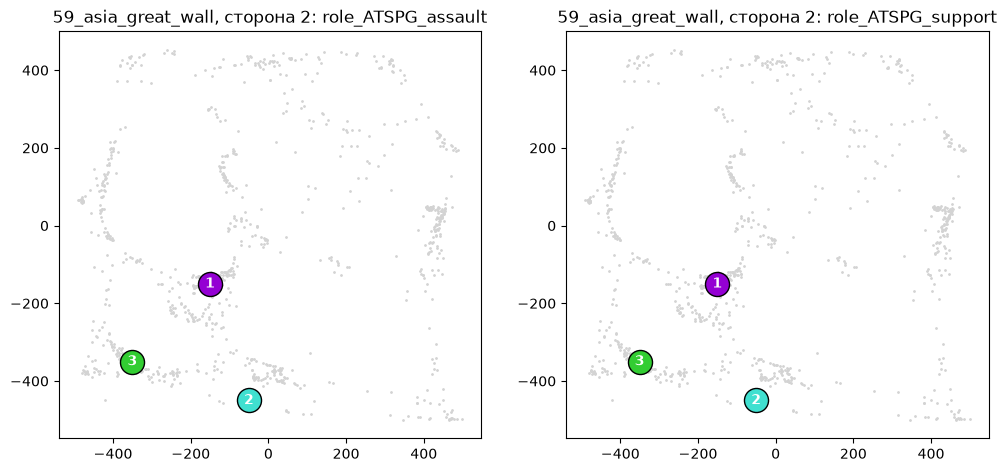

In [8]:
import matplotlib.pyplot as plt

MAP, TEAM = "59_asia_great_wall", 2
SHOW = ["role_ATSPG_assault", "role_ATSPG_support"]
COLORS = {1: "darkviolet", 2: "turquoise", 3: "limegreen"}

full = advice(dev, "role_group", BEST_K_GRP)
side = full[(full["map_name"] == MAP) & (full["team"] == TEAM)].copy()
side["rank"] = side.groupby("role_group")["score"].rank(ascending=False, method="first").astype(int)

points = dev[dev["map_name"] == MAP]
fig, axes = plt.subplots(1, len(SHOW), figsize=(12, 6))
for ax, role in zip(axes, SHOW):
    ax.scatter(points["x"], points["z"], s=1, c="lightgray")
    for row in side[side["role_group"] == role].itertuples():
        cx, cz = (row.zone_x + 0.5) * ZONE_SIZE, (row.zone_z + 0.5) * ZONE_SIZE
        ax.scatter(cx, cz, s=300, c=COLORS[row.rank], edgecolors="black")
        ax.text(cx, cz, str(row.rank), ha="center", va="center", color="white", weight="bold")
    ax.set_title(f"{MAP}, сторона {TEAM}: {role}")
    ax.set_aspect("equal")
plt.show()